# Fase 2 — Comprensión de los datos (EDA)

Análisis exploratorio del dataset **Fruit Quality Classification** (Kaggle, `ryandpark`).

Objetivos:
1. Inventario y distribución de clases (calidad × fruta) → **desbalanceo**.
2. Propiedades de las imágenes: resolución, brillo, nitidez.
3. **Duplicados** exactos y casi duplicados (riesgo de fuga de datos entre train y test).
4. Variabilidad visual: fondos, número de frutas por imagen.
5. Distribución del tamaño (diámetro normalizado) por fruta.
6. Primera mirada a la separabilidad buena vs. mala con características de color.

Todas las figuras se guardan en `reports/figures/` en **PDF (vectorial)** para el informe.

In [1]:
import sys, hashlib
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from tqdm.auto import tqdm

from fruitq.config import RAW_KAGGLE, FIGURES, PROCESSED, SEED
from fruitq.io import index_folder, read_image
from fruitq.segmentation import find_fruits, largest_fruit
from fruitq.size import normalized_diameter
from fruitq.features import extract_features, feature_names

FIGURES.mkdir(parents=True, exist_ok=True); PROCESSED.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

def savefig(name):
    plt.savefig(FIGURES / f"{name}.pdf", bbox_inches="tight")
    plt.savefig(FIGURES / f"{name}.png", bbox_inches="tight", dpi=150)

C:\Users\sebas\Desktop\APO III\Semana 14\proyectoFinal\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Inventario y distribución de clases

In [2]:
df = index_folder(RAW_KAGGLE).rename(columns={"level_0": "carpeta", "level_1": "subcarpeta"})
calidad_map = {"Good Quality_Fruits": "buena", "Bad Quality_Fruits": "mala", "Mixed Qualit_Fruits": "mixta"}
df["calidad"] = df["carpeta"].map(calidad_map)
fruit_map = {"Lemon": "Lime"}  # en mixed se llama Lemon; en good/bad, Lime
df["fruta"] = df["subcarpeta"].str.replace(r"_(Good|Bad)$", "", regex=True).replace(fruit_map)
tabla = pd.crosstab(df["fruta"], df["calidad"], margins=True, margins_name="Total")
tabla

calidad,buena,mala,mixta,Total
fruta,,,,
Apple,1149,1141,113,2403
Banana,1113,1087,285,2485
Guava,1152,1129,148,2429
Lime,1094,1085,278,2457
Orange,1216,1159,125,2500
Pomegranate,5940,1187,125,7252
Total,11664,6788,1074,19526


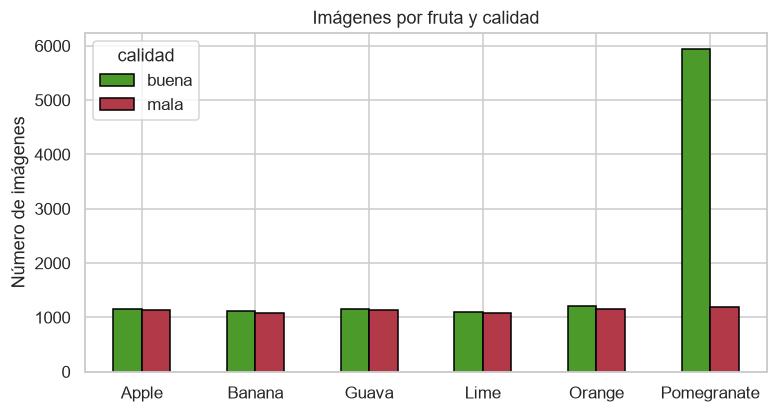

Razón de desbalanceo (máx/mín entre las 12 clases fruta×calidad): 5.47
Buena vs mala global: 11664 vs 6788


In [3]:
cnt = df[df.calidad != "mixta"].groupby(["fruta", "calidad"]).size().unstack()
ax = cnt.plot(kind="bar", figsize=(8, 4), color={"buena": "#4C9A2A", "mala": "#B23A48"}, edgecolor="black")
ax.set_ylabel("Número de imágenes"); ax.set_xlabel(""); ax.set_title("Imágenes por fruta y calidad")
plt.xticks(rotation=0); savefig("eda_distribucion_clases"); plt.show()

n = df[df.calidad != "mixta"].groupby(["fruta", "calidad"]).size()
print(f"Razón de desbalanceo (máx/mín entre las 12 clases fruta×calidad): {n.max() / n.min():.2f}")
print(f"Buena vs mala global: {(df.calidad=='buena').sum()} vs {(df.calidad=='mala').sum()}")

**Observaciones.** Las clases están balanceadas (~1100 imágenes) **excepto `Pomegranate_Good`**, que tiene ~5 veces más imágenes. Esto sesga la calidad global hacia `buena` y hay que tratarlo (submuestreo de granada buena o pesos de clase). El dataset solo trae **dos** niveles de calidad (buena / mala) más una carpeta `mixta` sin etiqueta por fruta. Para llegar a las **3 clases** que exige el enunciado se debe construir la clase intermedia (`regular`) con la anotación manual de los recortes de `mixed_quality` y de las fotos propias.

## 2. Propiedades de las imágenes: resolución, brillo y nitidez

In [4]:
def img_stats(path):
    raw = np.fromfile(path, dtype=np.uint8)
    img = cv2.imdecode(raw, cv2.IMREAD_COLOR)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    small = cv2.resize(gray, (8, 8), interpolation=cv2.INTER_AREA)
    ahash = "".join("1" if v else "0" for v in (small > small.mean()).ravel())
    return {
        "h": img.shape[0], "w": img.shape[1],
        "brillo": float(gray.mean()),
        "nitidez": float(cv2.Laplacian(gray, cv2.CV_64F).var()),
        "md5": hashlib.md5(raw.tobytes()).hexdigest(),
        "ahash": ahash,
        # Imagen en escala de grises guardada como RGB: los 3 canales casi iguales
        "gris": bool(np.abs(img[:, :, 0].astype(int) - img[:, :, 1]).mean() < 2
                     and np.abs(img[:, :, 1].astype(int) - img[:, :, 2]).mean() < 2),
    }

cache = PROCESSED / "eda_image_stats.csv"
if cache.exists():
    stats = pd.read_csv(cache, dtype={"ahash": str})
else:
    stats = pd.DataFrame([img_stats(p) for p in tqdm(df["path"], desc="Leyendo imágenes")])
    stats.insert(0, "path", df["path"].values)
    stats.to_csv(cache, index=False)
df = df.merge(stats, on="path")
df["resolucion"] = df["w"].astype(str) + "x" + df["h"].astype(str)
df["resolucion"].value_counts().head(8)

resolucion
256x256      12508
192x256       4536
256x192       1897
3000x4000      381
8000x6000      183
144x256         12
256x144          9
Name: count, dtype: int64

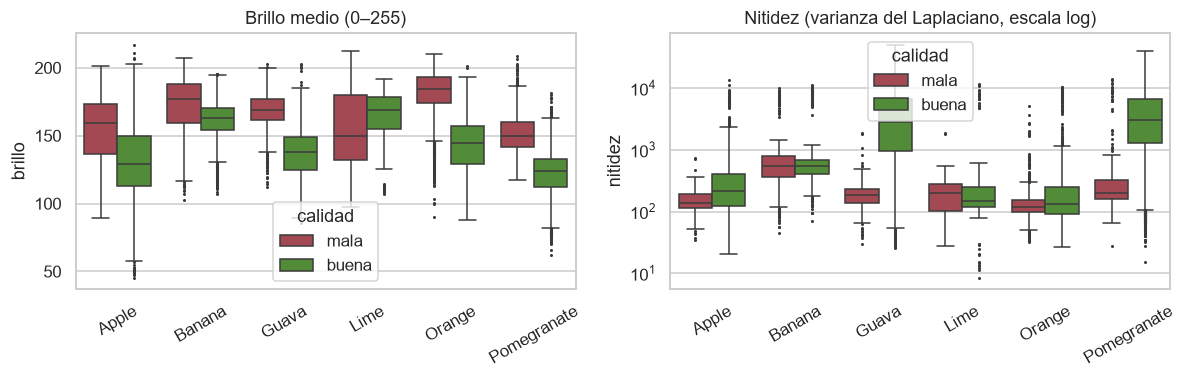

Imágenes potencialmente borrosas (var. Laplaciano < 50): 167 (0.9%)


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
sub = df[df.calidad != "mixta"]
sns.boxplot(data=sub, x="fruta", y="brillo", hue="calidad", ax=axes[0],
            palette={"buena": "#4C9A2A", "mala": "#B23A48"}, fliersize=1)
axes[0].set_title("Brillo medio (0–255)"); axes[0].set_xlabel("")
sns.boxplot(data=sub, x="fruta", y="nitidez", hue="calidad", ax=axes[1],
            palette={"buena": "#4C9A2A", "mala": "#B23A48"}, fliersize=1, log_scale=True)
axes[1].set_title("Nitidez (varianza del Laplaciano, escala log)"); axes[1].set_xlabel("")
for ax in axes: ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); savefig("eda_brillo_nitidez"); plt.show()

umbral_borrosa = 50
print(f"Imágenes potencialmente borrosas (var. Laplaciano < {umbral_borrosa}): "
      f"{(df.nitidez < umbral_borrosa).sum()} ({(df.nitidez < umbral_borrosa).mean():.1%})")

In [6]:
print("Imágenes en escala de grises por subcarpeta:")
print(df[df.gris].groupby("subcarpeta").size().to_string())

Imágenes en escala de grises por subcarpeta:
subcarpeta
Pomegranate_Good    1188


**Hallazgo.** Todas las imágenes en escala de grises están en `Pomegranate_Good`. Son copias aumentadas de fotos a color (ver sección 3), y explican buena parte de su exceso de imágenes. Como el **color es la señal principal de calidad** (manchas, podredumbre), se **eliminan** en la preparación de datos.

## 3. Duplicados (riesgo de fuga de información)

In [7]:
dup_exact = df[df.duplicated("md5", keep=False)]
dup_near = df[df.duplicated("ahash", keep=False)]
print(f"Duplicados exactos (mismo MD5): {df.duplicated('md5').sum()} imágenes sobrantes")
print(f"Casi duplicados (mismo average-hash 8x8): {df.duplicated('ahash').sum()} imágenes sobrantes")
print()
print("Casi duplicados por subcarpeta:")
print(df[df.duplicated("ahash")].groupby("subcarpeta").size().sort_values(ascending=False).head(12).to_string())

cross = df.groupby("ahash")["calidad"].nunique()
print(f"\nGrupos de casi duplicados con etiquetas DISTINTAS: {(cross > 1).sum()}")

Duplicados exactos (mismo MD5): 0 imágenes sobrantes
Casi duplicados (mismo average-hash 8x8): 5874 imágenes sobrantes

Casi duplicados por subcarpeta:
subcarpeta
Pomegranate_Good    1894
Lime_Good            695
Pomegranate_Bad      600
Guava_Bad            536
Orange_Bad           502
Lime_Bad             387
Apple_Bad            385
Banana_Good          361
Banana_Bad           341
Orange_Good          142
Apple_Good            15
Lemon                  7

Grupos de casi duplicados con etiquetas DISTINTAS: 19


**Por qué importa.** Si una imagen y su copia (o una versión rotada o recortada) quedan una en *train* y otra en *test*, la métrica de test sobreestima la generalización (*data leakage*). La partición se debe hacer **por grupo de hash** (`GroupShuffleSplit`), no imagen por imagen. El average-hash solo detecta copias casi idénticas; las versiones aumentadas (rotadas o volteadas) requieren hashes invariantes. Esto se revisa visualmente abajo.

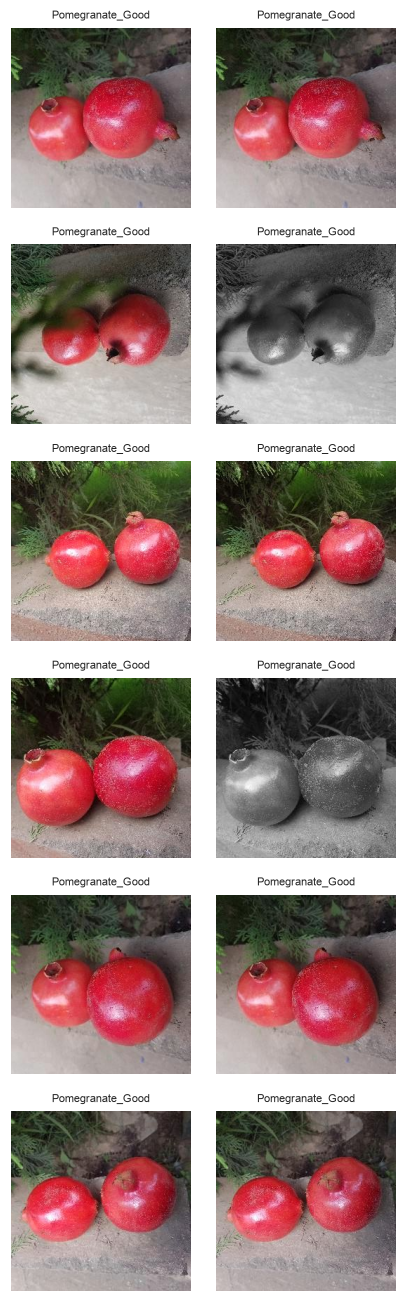

In [8]:
grp = df[df.duplicated("ahash", keep=False)].groupby("ahash")
ejemplos = [g for _, g in grp if len(g) >= 2][:6]
if ejemplos:
    fig, axes = plt.subplots(len(ejemplos), 2, figsize=(4, 2 * len(ejemplos)))
    axes = np.atleast_2d(axes)
    for i, g in enumerate(ejemplos):
        for j in range(2):
            r = g.iloc[j]
            axes[i, j].imshow(cv2.cvtColor(read_image(r.path), cv2.COLOR_BGR2RGB))
            axes[i, j].set_title(f"{r.subcarpeta}", fontsize=7); axes[i, j].axis("off")
    plt.tight_layout(); plt.show()

## 4. Variabilidad visual

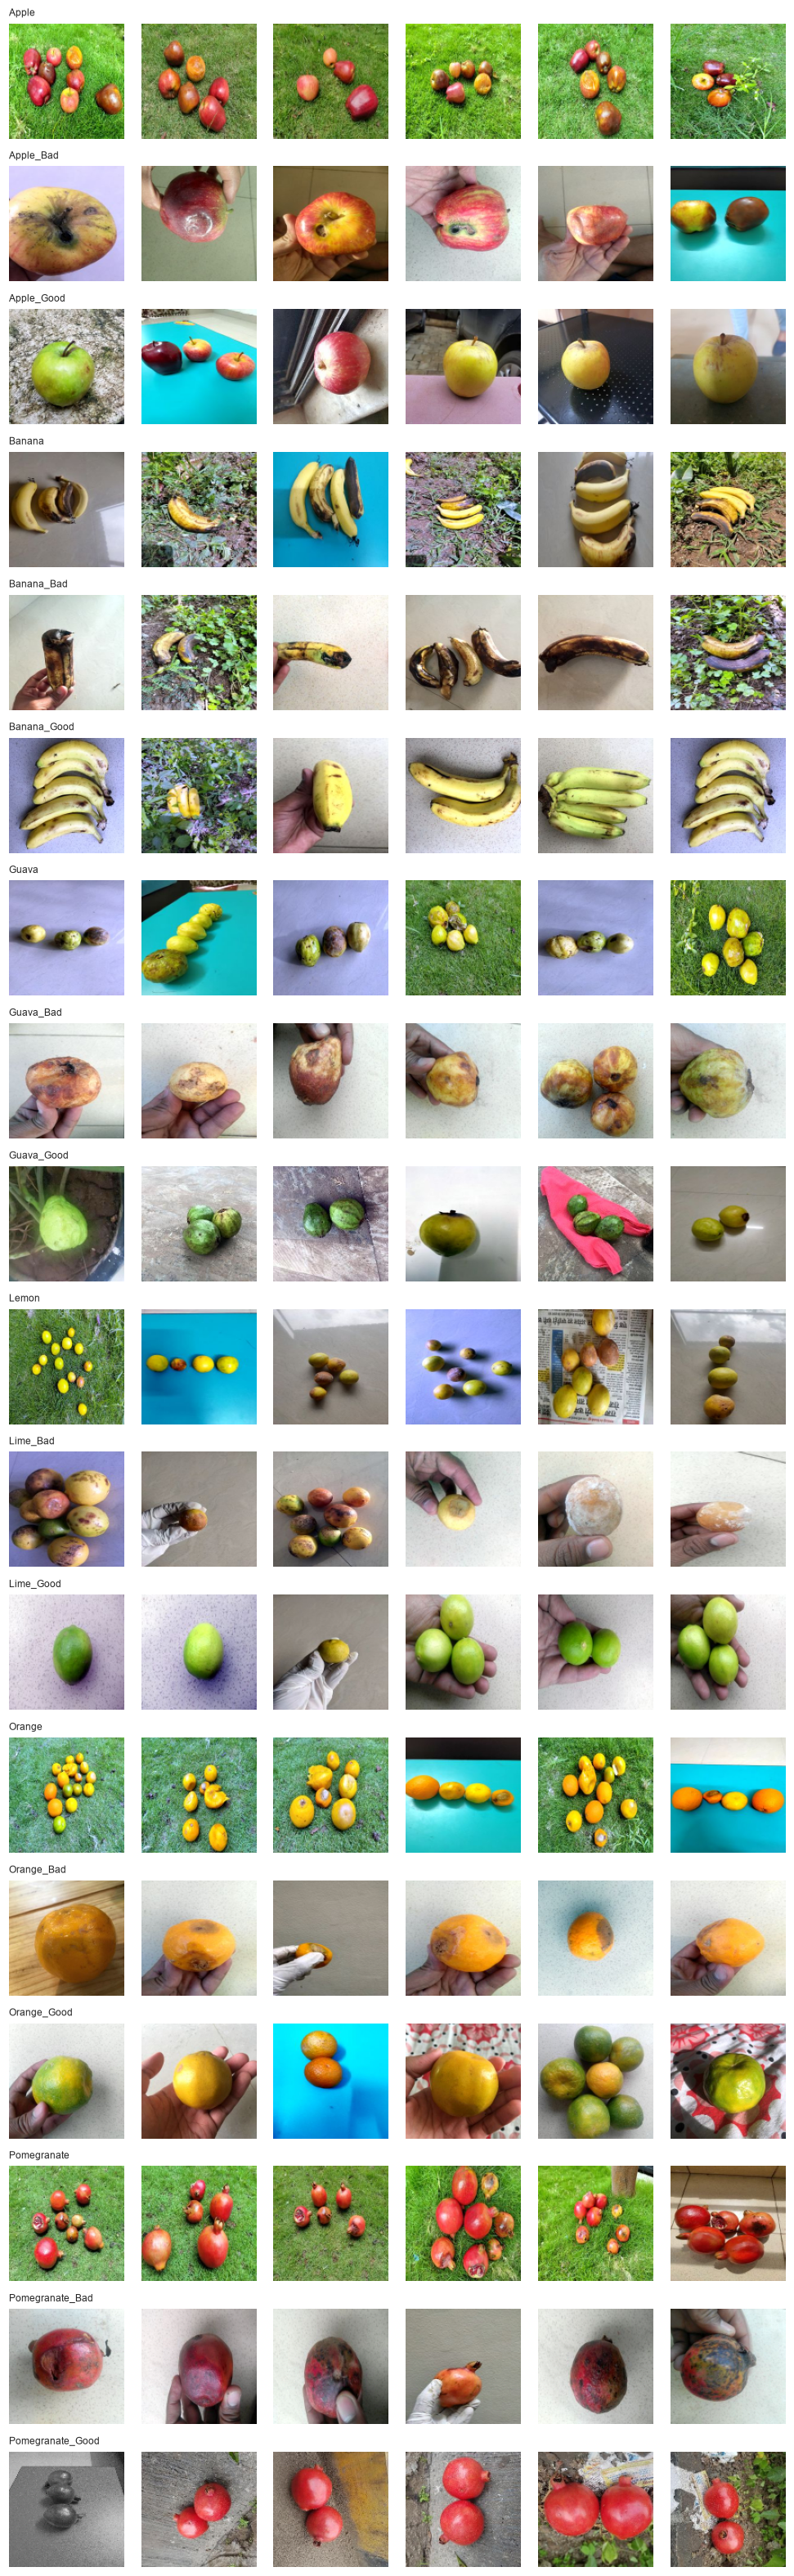

In [9]:
rng = np.random.default_rng(SEED)
grupos = sorted(df.subcarpeta.unique())
fig, axes = plt.subplots(len(grupos), 6, figsize=(9, 1.6 * len(grupos)))
for i, s in enumerate(grupos):
    paths = df[df.subcarpeta == s].sample(6, random_state=SEED).path
    for j, p in enumerate(paths):
        axes[i, j].imshow(cv2.cvtColor(cv2.resize(read_image(p), (128, 128)), cv2.COLOR_BGR2RGB))
        axes[i, j].axis("off")
    axes[i, 0].set_title(s, fontsize=8, loc="left")
plt.tight_layout(); savefig("eda_mosaico"); plt.show()

**Observaciones.** El supuesto del enunciado ("una fruta sobre fondo uniforme") **no se cumple** en buena parte del dataset. Hay manos sosteniendo la fruta, pasto, baldosas, cartulinas de colores y varias frutas por foto, también en las carpetas buena y mala. Consecuencias:
- Un modelo podría aprender **atajos** del fondo (p. ej. "pasto ⇒ mixta") en lugar de la fruta. Por eso se segmenta y se enmascara el fondo antes de extraer características.
- La segmentación con un umbral simple no basta. Se usa un modelo del color del fondo tomado del borde de la imagen, más GrabCut y watershed (ver `src/fruitq/segmentation.py`).

Segmentando muestra:   0%|          | 0/480 [00:00<?, ?it/s]

Segmentando muestra:   0%|          | 1/480 [00:01<08:58,  1.12s/it]

Segmentando muestra:   0%|          | 2/480 [00:01<04:24,  1.81it/s]

Segmentando muestra:   1%|          | 3/480 [00:01<02:53,  2.75it/s]

Segmentando muestra:   1%|          | 4/480 [00:01<02:26,  3.24it/s]

Segmentando muestra:   1%|          | 5/480 [00:01<02:06,  3.74it/s]

... (416 outputs left out)

Segmentando muestra: 100%|█████████▉| 478/480 [02:08<00:00,  7.13it/s]

Segmentando muestra: 100%|█████████▉| 479/480 [02:08<00:00,  7.45it/s]

Segmentando muestra: 100%|██████████| 480/480 [02:08<00:00,  7.71it/s]

Segmentando muestra: 100%|██████████| 480/480 [02:08<00:00,  3.72it/s]

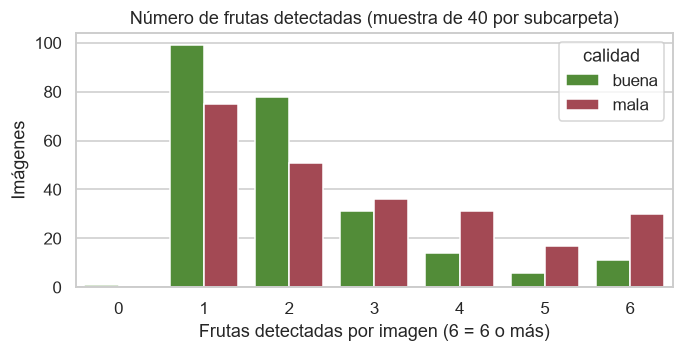

Imágenes con exactamente 1 fruta: 36.2%


In [10]:
muestra = df[df.calidad != "mixta"].groupby("subcarpeta").sample(40, random_state=SEED)
filas = []
for r in tqdm(muestra.itertuples(), total=len(muestra), desc="Segmentando muestra"):
    img = read_image(r.path)
    regs = find_fruits(img)
    fila = {"path": r.path, "fruta": r.fruta, "calidad": r.calidad, "n_frutas": len(regs)}
    if regs:
        main = regs[0]
        fila["d_norm"] = normalized_diameter(main.area, img.shape)
        f = extract_features(main.crop, main.mask)
        fila.update(dict(zip(feature_names(), f)))
    filas.append(fila)
seg = pd.DataFrame(filas)
seg.to_csv(PROCESSED / "eda_muestra_segmentada.csv", index=False)

fig, ax = plt.subplots(figsize=(7, 3))
seg["n_frutas_c"] = seg["n_frutas"].clip(upper=6)
sns.countplot(data=seg, x="n_frutas_c", hue="calidad", palette={"buena": "#4C9A2A", "mala": "#B23A48"}, ax=ax)
ax.set_xlabel("Frutas detectadas por imagen (6 = 6 o más)"); ax.set_ylabel("Imágenes")
ax.set_title("Número de frutas detectadas (muestra de 40 por subcarpeta)")
savefig("eda_frutas_por_imagen"); plt.show()
print(f"Imágenes con exactamente 1 fruta: {(seg.n_frutas == 1).mean():.1%}")

## 5. Distribución del tamaño (diámetro equivalente normalizado)

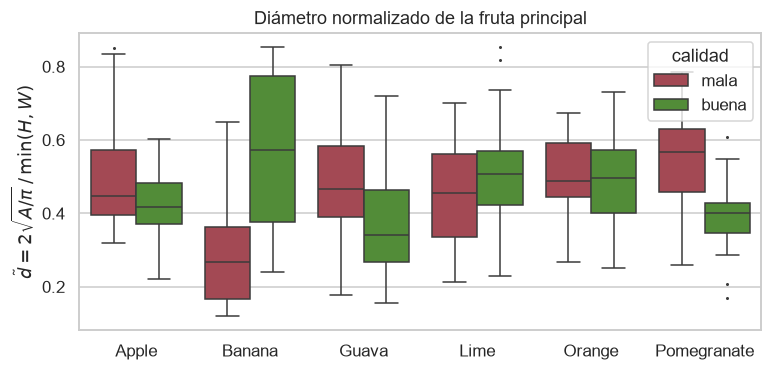

,mean,std,min,50%,max
fruta,,,,,
Apple,0.463484,0.120801,0.222011,0.430024,0.851918
Banana,0.429331,0.223035,0.119507,0.374875,0.854191
Guava,0.427809,0.145590,0.156955,0.429306,0.804172
Lime,0.487303,0.144057,0.213278,0.493228,0.854014
Orange,0.496738,0.109016,0.249787,0.492055,0.732115
Pomegranate,0.469342,0.126830,0.168563,0.434570,0.786472


In [11]:
fig, ax = plt.subplots(figsize=(8, 3.5))
sns.boxplot(data=seg.dropna(subset=["d_norm"]), x="fruta", y="d_norm", hue="calidad",
            palette={"buena": "#4C9A2A", "mala": "#B23A48"}, fliersize=1, ax=ax)
ax.set_ylabel(r"$\tilde d = 2\sqrt{A/\pi}\,/\,\min(H,W)$"); ax.set_xlabel("")
ax.set_title("Diámetro normalizado de la fruta principal")
savefig("eda_tamano"); plt.show()
seg.groupby("fruta")["d_norm"].describe()[["mean", "std", "min", "50%", "max"]]

**Observaciones.** En Kaggle la distancia de la cámara **no está controlada**, así que $\tilde d$ mezcla el tamaño real con el encuadre. Los terciles calculados sobre Kaggle **no** representan el tamaño físico. Para las fotos propias se fija la distancia (protocolo en `data/README.md`) y se calibran los umbrales con ellas, idealmente con una moneda de referencia para convertir a cm.

## 6. Primera mirada a la separabilidad (características de color y defectos)

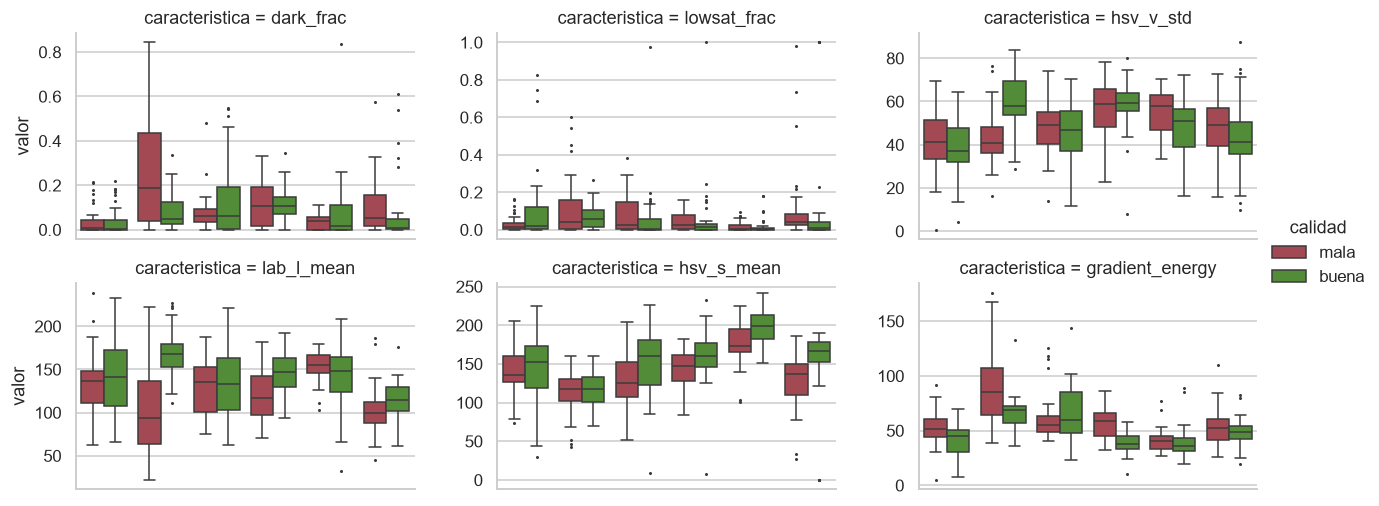

In [12]:
cols = ["dark_frac", "lowsat_frac", "hsv_v_std", "lab_l_mean", "hsv_s_mean", "gradient_energy"]
long = seg.melt(id_vars=["fruta", "calidad"], value_vars=cols, var_name="caracteristica", value_name="valor")
g = sns.catplot(data=long, x="fruta", y="valor", hue="calidad", col="caracteristica", col_wrap=3,
                kind="box", sharey=False, height=2.6, aspect=1.5, fliersize=1,
                palette={"buena": "#4C9A2A", "mala": "#B23A48"})
g.set_xticklabels(rotation=30); g.set_xlabels("")
plt.savefig(FIGURES / "eda_separabilidad.pdf", bbox_inches="tight"); plt.show()

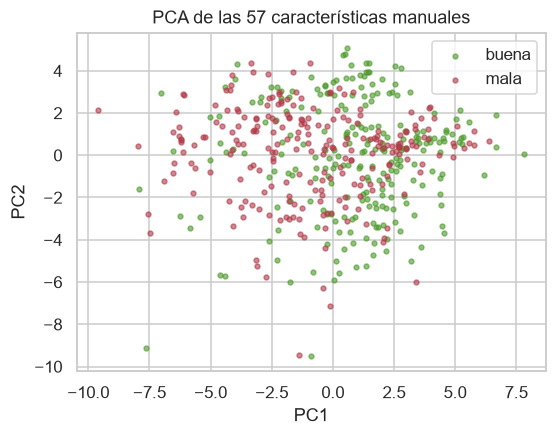

In [13]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
X = seg[feature_names()].dropna()
y = seg.loc[X.index, "calidad"]
Z = PCA(n_components=2, random_state=SEED).fit_transform(StandardScaler().fit_transform(X))
fig, ax = plt.subplots(figsize=(5.5, 4))
for c, col in (("buena", "#4C9A2A"), ("mala", "#B23A48")):
    m = (y == c).values
    ax.scatter(Z[m, 0], Z[m, 1], s=10, alpha=0.6, label=c, color=col)
ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.legend(); ax.set_title("PCA de las 57 características manuales")
savefig("eda_pca"); plt.show()

## Resumen de hallazgos (para `docs/fases/02_comprension_datos.md`)

Completar con los números que imprimen las celdas de arriba:
1. **Tamaño:** ~19.5k imágenes JPG de baja resolución (~256 px), 6 frutas, 2 calidades más una carpeta mixta.
2. **Desbalanceo:** `Pomegranate_Good` ≈ 5× las demás clases.
3. **Duplicados:** ver la sección 3. Se debe partir **por grupo** para evitar fuga de información.
4. **Fondos heterogéneos y varias frutas por imagen:** se requiere segmentación robusta y enmascarar el fondo.
5. **Tamaño:** $\tilde d$ de Kaggle no es comparable entre fotos; se calibra con las fotos propias.
6. **Tercera clase de calidad:** no existe en el dataset y se construye con anotación manual.